# 301. Kill test 1: can kmerseek pin the start and end of short protein features?

**The question.** Given a whole protein, can kmerseek report the start and end of its short
features (signal peptides, transit peptides, transmembrane spans, ELM short linear motifs)
to within 4 residues, at a false-positive rate on decoys below 1%, faster than the CPU tools
people use now?

**The decision this informs.** Whether the paper can offer kmerseek as a tool that places
short features on a protein. If it fails, that use comes out of the paper, and kmerseek is
described only as a search that finds related proteins.

**Words.**
- A *kmerseek setting* is one combination of alphabet, k-size, scaled, extension and mask.
- A *feature* is a Swiss-Prot or ELM annotated stretch shorter than 60 residues.
- A *region* is the stretch kmerseek reports for a hit. For the scans below, the stretch a
  scan reports is called a *call*.
- *Boundary error* is |predicted start − true start| + |predicted end − true end|, in
  residues. 0 is perfect; larger is worse.
- A *decoy window* is a feature's own residues put back into its parent protein in a new
  order (step 3). A hit on a decoy window is a false positive.

**The pass/fail rule, fixed before any kmerseek run (task brief, 2026-10-20).** Set a
regional E-value threshold at which fewer than 1.0% of decoy windows produce a hit. At that
threshold:

PASS if all three hold:
1. kmerseek recalls more than 80% of true features. A feature is recalled when a reported
   region overlaps it by at least one residue; the overlap fraction is reported too.
2. Median boundary error is 4 residues or fewer.
3. One whole-protein query takes under 100 ms wall-clock on 4 CPU cores with a cold disk
   cache.

DROP THE IDEA if recall falls below 50% at that threshold, or if median boundary error is 8
residues or more. Anything in between is FAIL, reported with the numbers. The rule is not
changed after the first result. If it turns out to be the wrong rule, this notebook says so
and still reports the verdict under it.

Higher recall is better. Lower boundary error is better. A method whose recall equals its
decoy hit rate is no better than chance.

**Status, 2026-10-20.** Step 1 (the scans) is done and below. Step 2 (the 2,000 real queries,
the 500 chimeras, their UniRef90 clusters and the Swiss-Prot search database) is done and
in section 2. Step 3 and the pilot are complete; section 5 scores three completed settings and records recovery of 16 memory failures. The last
section lists what was found while preparing them and the decisions taken.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

sys.path.insert(0, str(Path.cwd()))
import pubfig as pf

pf.use_style()
pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_cols(20)
pl.Config.set_tbl_width_chars(200)

TABLES = Path("../tables")
DATA = Path("../data/301_short_feature_boundaries")
FIG = Path("../figures")

curve = pl.read_csv(TABLES / "301_step1_scan_curve_nb244_swissprot.csv")
feats = pl.read_csv(TABLES / "301_step1_scan_features_nb244_swissprot.csv")
summary = pl.read_csv(TABLES / "301_step1_scan_summary_nb244_swissprot.csv")
cases = pl.read_csv(DATA / "step1_cases_nb244_swissprot.tsv", separator="\t")

SCAN_COLOUR = {"hydropathy": pf.OKABE_ITO["blue"], "period": pf.OKABE_ITO["vermillion"]}
SCAN_LABEL = {
    "hydropathy": "hydropathy window scan (Kyte-Doolittle, 19 aa)",
    "period": "period scan (H/P autocorrelation, 19 aa, lags 1-9)",
}
DECOY_RULE = "decoy hit rate below 1%"
KD_RULE = "Kyte-Doolittle 1982 cutoff 1.6 (context, not the pass rule)"
DECOY_LIMIT = 0.01
RECALL_PASS, RECALL_DROP = 0.80, 0.50
ERROR_PASS, ERROR_DROP = 4, 8


def read_fasta(path):
    seqs, acc = {}, None
    for line in Path(path).read_text().splitlines():
        if line.startswith(">"):
            acc = line[1:].split()[0]
            seqs[acc] = []
        else:
            seqs[acc].append(line.strip())
    return {k: "".join(v) for k, v in seqs.items()}


human = read_fasta(DATA / "step1_queries_nb244_human_swissprot.fasta")
decoy_seqs = read_fasta(DATA / "step1_decoys_nb244_swissprot.fasta")

## 1. Step 1: the scans that need no search, on notebook 244's 87 cases

[Notebook 231](https://github.com/seanome/2024-kmerseek-analysis/blob/main/notebooks/231_swissprot_composition_controls.ipynb)
showed a Kyte-Doolittle hydropathy window beat all 406 kmerseek settings on Swiss-Prot.
[Notebook 244](https://github.com/seanome/2024-kmerseek-analysis/pull/78) named that scan as
the control for its 87 short-feature cases and recorded only whether it landed on them (1 of
87), not its recall at a fixed false-positive rate or its boundary error. This section
records both, for that scan and for a period scan, under the pass rule above. Their numbers
are the bar for kmerseek.

**Data.** The 87 rows of notebook 244's candidate table admitted under "all criteria"
(`tables/244_hero_candidates.csv`, PR 78 at commit 9e6434f5), copied to
`data/301_short_feature_boundaries/step1_cases_nb244_swissprot.tsv`, and their human
Swiss-Prot sequences (`step1_queries_nb244_human_swissprot.fasta`, from the same commit's
`244_case_sequences.fasta`). The midi-plus run, 998 human chr6/MHC-region queries, Swiss-Prot
features. A case is one human feature in one target species. A scan reads only the human
protein, so it gives the same answer for every species of a feature: the 87 cases are 50
distinct human features on 42 proteins. Recall is given both ways.

**The scans** (`scripts/score_301_step1_scans.py`). Both slide a 19-residue window, notebook
231's window.
- Hydropathy: the window's mean Kyte-Doolittle hydropathy.
- Period: the protein written as hydrophobic +1 / polar −1 in hp_pbotc_1st_ed2's classes
  (hydrophobic `ACFILMPVWY`, polar `DEGHKNQRST`), as in
  [notebook 295](https://github.com/seanome/2024-kmerseek-analysis/pull/141)'s period scan. The
  window's score is its largest autocorrelation over lags 1 to 9 (the mean of x[i]·x[i+lag]
  over the pairs inside the window). Notebook 295 used lags 1 to 30 on whole proteins; a
  19-residue window has no lag 30, and lags past 9 have fewer than 10 pairs.

A call is every run of windows scoring above the threshold, reported as the residues those
windows cover. The threshold is the lowest one at which fewer than 1% of decoy windows are
hit.

**Decoys** (step 3's recipe, applied to these 50 features). For each feature, two copies of
the parent protein with the feature's residues replaced by (a) a di-residue shuffle: the
window cut into adjacent pairs and the pairs put in random order (seed 301), and (b) the
window reversed. That is 100 decoy windows, so "fewer than 1%" means none hit.

The feature types of the 87 cases are not the four types of the main test (signal peptides,
transit peptides, transmembrane spans, ELM motifs). Only 4 of the 87 are TRANSMEM; none is a
signal or transit peptide or an ELM motif.

shape: (7, 4)
┌──────────────┬─────────┬────────────┬──────────────────┐
│ feature_type ┆ n_cases ┆ n_features ┆ median_length_aa │
│ ---          ┆ ---     ┆ ---        ┆ ---              │
│ str          ┆ u32     ┆ u32        ┆ f64              │
╞══════════════╪═════════╪════════════╪══════════════════╡
│ BINDING      ┆ 31      ┆ 9          ┆ 9.0              │
│ INTRAMEM     ┆ 16      ┆ 6          ┆ 20.0             │
│ REPEAT       ┆ 13      ┆ 12         ┆ 33.0             │
│ ZN_FING      ┆ 13      ┆ 11         ┆ 23.0             │
│ DOMAIN       ┆ 8       ┆ 7          ┆ 51.0             │
│ TRANSMEM     ┆ 4       ┆ 4          ┆ 21.0             │
│ DNA_BIND     ┆ 2       ┆ 1          ┆ 24.0             │
└──────────────┴─────────┴────────────┴──────────────────┘
total: 87 cases, 50 features, 42 proteins


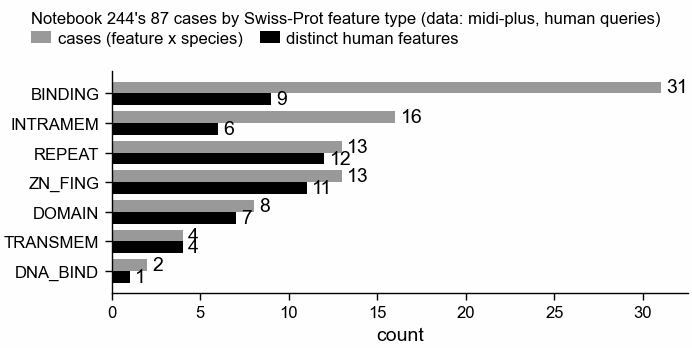

In [2]:
by_type = (
    cases.group_by("feature_type")
    .agg(
        n_cases=pl.len(),
        n_features=pl.struct("query", "feature_start", "feature_end").n_unique(),
        median_length_aa=pl.col("feature_length_aa").median(),
    )
    .sort("n_cases", descending=True)
)
print(by_type)
print(
    f"total: {cases.height} cases, "
    f"{cases.select('query', 'feature_start', 'feature_end').n_unique()} features, "
    f"{cases['query'].n_unique()} proteins"
)

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 45)
y = np.arange(by_type.height)
ax.barh(
    y - 0.2,
    by_type["n_cases"],
    height=0.4,
    color=pf.GREY,
    label="cases (feature x species)",
)
ax.barh(
    y + 0.2,
    by_type["n_features"],
    height=0.4,
    color="black",
    label="distinct human features",
)
ax.set_yticks(y, by_type["feature_type"])
ax.invert_yaxis()
ax.set_xlabel("count")
for yi, (c, f) in enumerate(zip(by_type["n_cases"], by_type["n_features"])):
    ax.text(c + 0.3, yi - 0.2, str(c), va="center")
    ax.text(f + 0.3, yi + 0.2, str(f), va="center")
pf.shared_legend(
    fig,
    ncol=2,
    title=(
        "Notebook 244's 87 cases by Swiss-Prot feature type (data: midi-plus, human queries)"
    ),
    alignment="left",
)
pf.save(fig, FIG / "301_step1_case_types_nb244_swissprot", formats=("png", "pdf"))

### SF1. Recall against decoy hit rate, for each scan

How to read it: each curve traces one scan as its threshold moves from strict (bottom left)
to loose (top right). The grey dashed diagonal is a scan whose recall equals its decoy hit
rate, which is no better than chance. The pass rule reads each curve at the black dotted
line, a decoy hit rate of 1%. Above the diagonal is better than chance; the pass rule needs
recall above 0.8 left of the dotted line. Panel a pools all 50 features; panels b to h split
them by Swiss-Prot feature type, with the number of features in each title.

Features whose real window score is above both of its decoys' scores:
shape: (7, 4)
┌──────────────┬────────────┬────────────┬────────┐
│ feature_type ┆ n_features ┆ hydropathy ┆ period │
│ ---          ┆ ---        ┆ ---        ┆ ---    │
│ str          ┆ i64        ┆ i64        ┆ i64    │
╞══════════════╪════════════╪════════════╪════════╡
│ BINDING      ┆ 9          ┆ 0          ┆ 2      │
│ INTRAMEM     ┆ 6          ┆ 0          ┆ 0      │
│ REPEAT       ┆ 12         ┆ 3          ┆ 1      │
│ ZN_FING      ┆ 11         ┆ 2          ┆ 4      │
│ DOMAIN       ┆ 7          ┆ 2          ┆ 1      │
│ TRANSMEM     ┆ 4          ┆ 1          ┆ 1      │
│ DNA_BIND     ┆ 1          ┆ 0          ┆ 0      │
└──────────────┴────────────┴────────────┴────────┘
shape: (2, 3)
┌────────────┬──────────────────────────┬────────────┐
│ scan       ┆ n_real_beats_both_decoys ┆ n_features │
│ ---        ┆ ---                      ┆ ---        │
│ str        ┆ i64                      ┆ i64        │
╞═════

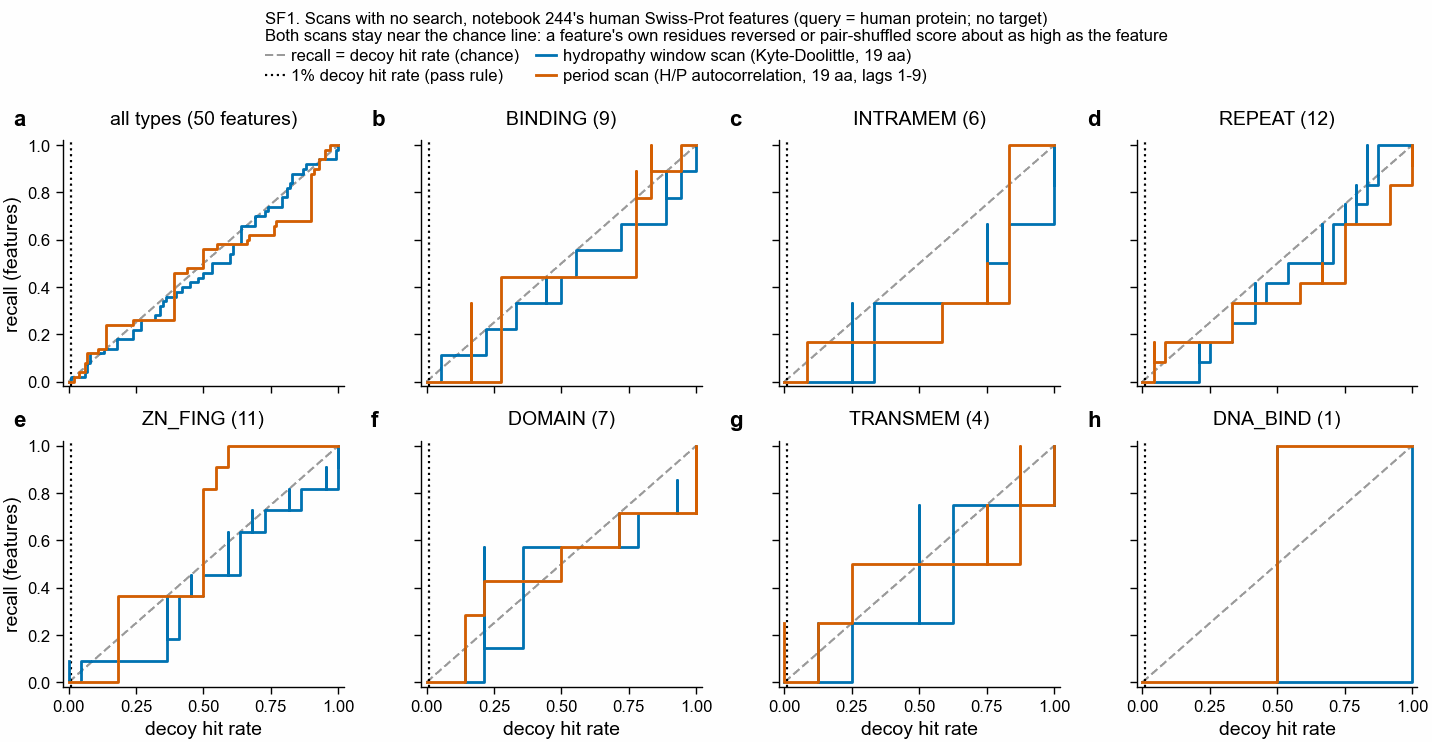

In [3]:
types = by_type["feature_type"].to_list()
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 95, nrows=2, ncols=4, sharex=True, sharey=True)
axs = axs.ravel()


def draw(ax, rows_by_scan, title):
    ax.plot(
        [0, 1],
        [0, 1],
        color=pf.GREY,
        ls="--",
        lw=0.8,
        label="recall = decoy hit rate (chance)",
    )
    ax.axvline(
        DECOY_LIMIT,
        color="black",
        ls=":",
        lw=0.8,
        label="1% decoy hit rate (pass rule)",
    )
    for scan, (x, yv) in rows_by_scan.items():
        ax.step(x, yv, where="post", color=SCAN_COLOUR[scan], label=SCAN_LABEL[scan])
    ax.set_title(title)
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.02)


def curve_for(f_best, d_best):
    grid = np.unique(np.concatenate([f_best, d_best, [-np.inf]]))
    x = np.array([(d_best > t).mean() for t in grid])
    yv = np.array([(f_best > t).mean() for t in grid])
    o = np.argsort(x, kind="stable")
    return x[o], yv[o]


# Pooled curves come from the scoring script's own table.
pooled = {}
for scan in SCAN_COLOUR:
    c = curve.filter(pl.col("scan") == scan).sort("decoy_hit_rate", "recall_features")
    pooled[scan] = (c["decoy_hit_rate"].to_numpy(), c["recall_features"].to_numpy())
draw(axs[0], pooled, "all types (50 features)")

# Per type: recompute from the per-feature best window scores and the decoy sequences.
sys.path.insert(0, str(Path("../scripts").resolve()))
import score_301_step1_scans as s1

decoy_best = {}
fb = feats.filter(pl.col("threshold_rule") == DECOY_RULE)
for scan, fn in s1.SCANS.items():
    for r in fb.filter(pl.col("scan") == scan).iter_rows(named=True):
        key = f"{r['query']}|{r['feature_start']}-{r['feature_end']}"
        decoy_best[(scan, r["feature_id"])] = [
            s1.best_window_over(
                fn(decoy_seqs[f"{key}|{k}"]), r["feature_start"], r["feature_end"]
            )
            for k in ("dishuffle", "reversed")
        ]
per_type_rows = []
for ax, t in zip(axs[1:], types):
    rows = {}
    for scan in SCAN_COLOUR:
        sub = fb.filter((pl.col("scan") == scan) & (pl.col("feature_type") == t))
        f_best = sub["best_window_score"].to_numpy()
        d_best = np.array(
            [v for fid in sub["feature_id"] for v in decoy_best[(scan, fid)]]
        )
        rows[scan] = curve_for(f_best, d_best)
        n_beats = int(
            sum(
                f > max(decoy_best[(scan, fid)])
                for f, fid in zip(f_best, sub["feature_id"])
            )
        )
        per_type_rows.append(
            {
                "scan": scan,
                "feature_type": t,
                "n_features": sub.height,
                "n_real_beats_both_decoys": n_beats,
            }
        )
    draw(ax, rows, f"{t} ({sub.height})")
for ax in axs[len(types) + 1 :]:
    ax.set_visible(False)
for ax in axs[4:]:
    ax.set_xlabel("decoy hit rate")
for ax in axs[::4]:
    ax.set_ylabel("recall (features)")
for ax, letter in zip(axs, "abcdefgh"):
    if ax.get_visible():
        pf.panel_label(ax, letter)
pf.shared_legend(
    fig,
    ncol=2,
    title=(
        "SF1. Scans with no search, notebook 244's human Swiss-Prot features (query = human protein; no target)\n"
        "Both scans stay near the chance line: a feature's own residues reversed or pair-shuffled score about as high as the feature"
    ),
    alignment="left",
)
pf.save(
    fig,
    FIG / "301_sf1_scan_recall_vs_decoy_rate_nb244_swissprot",
    formats=("png", "pdf"),
)

beats = pl.DataFrame(per_type_rows)
print("Features whose real window score is above both of its decoys' scores:")
print(
    beats.pivot(
        on="scan",
        index=["feature_type", "n_features"],
        values="n_real_beats_both_decoys",
    )
)
print(
    beats.group_by("scan").agg(
        pl.col("n_real_beats_both_decoys").sum(), pl.col("n_features").sum()
    )
)
gap = (
    curve.with_columns(gap=pl.col("recall_features") - pl.col("decoy_hit_rate"))
    .group_by("scan")
    .agg(largest_recall_minus_decoy_rate=pl.col("gap").max().round(3))
)
print(gap)

### The pass rule applied to the scans

The table is `tables/301_step1_scan_summary_nb244_swissprot.csv`, column names as the scoring
script wrote them. `recall_features` counts the 50 distinct features; `recall_cases` weights
each by its number of species in the 87 cases. `ms_per_protein_warm` is the scan's time per
protein on the laptop, one core, sequences in memory: a warm number, not the cold-cache
timing of the pass rule.

The Kyte-Doolittle row at threshold 1.6 is context only. 1.6 is Kyte and Doolittle's 1982
cutoff for a membrane-spanning window, the one notebook 231 used; it is not set on decoys.

shape: (3, 11)
┌────────────┬──────────────────────┬───────────┬──────────────┬─────────────────┬────────────────┬─────────────────┬──────────────┬──────────────────────┬──────────────────────┬─────────────────────┐
│ scan       ┆ threshold_rule       ┆ threshold ┆ n_decoys_hit ┆ n_decoy_windows ┆ decoy_hit_rate ┆ recall_features ┆ recall_cases ┆ median_boundary_erro ┆ median_overlap_fract ┆ ms_per_protein_warm │
│ ---        ┆ ---                  ┆ ---       ┆ ---          ┆ ---             ┆ ---            ┆ ---             ┆ ---          ┆ r_aa                 ┆ ion                  ┆ ---                 │
│ str        ┆ str                  ┆ f64       ┆ i64          ┆ i64             ┆ f64            ┆ f64             ┆ f64          ┆ ---                  ┆ ---                  ┆ f64                 │
│            ┆                      ┆           ┆              ┆                 ┆                ┆                 ┆              ┆ f64                  ┆ f64                  ┆   

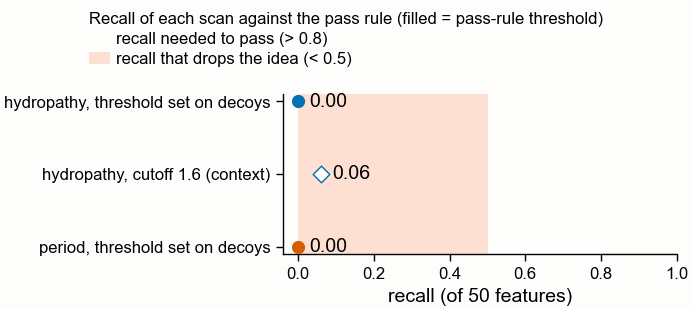

In [4]:
show = summary.select(
    "scan",
    "threshold_rule",
    pl.col("threshold").round(3),
    "n_decoys_hit",
    "n_decoy_windows",
    "decoy_hit_rate",
    "recall_features",
    pl.col("recall_cases").round(3),
    "median_boundary_error_aa",
    pl.col("median_overlap_fraction").round(2),
    pl.col("ms_per_protein_warm").round(3),
)
print(show)


def verdict(recall, err):
    if recall < RECALL_DROP or (err is not None and err >= ERROR_DROP):
        return "DROP"
    if recall > RECALL_PASS and err is not None and err <= ERROR_PASS:
        return "PASS (timing not tested)"
    return "FAIL"


fig, ax = pf.figure(pf.ONE_COLUMN_MM, 40)
ax.axvspan(RECALL_PASS, 1.0, color="#e5f5e0", label="recall needed to pass (> 0.8)")
ax.axvspan(0, RECALL_DROP, color="#fee0d2", label="recall that drops the idea (< 0.5)")
rows = summary.with_row_index("i")
for r in rows.iter_rows(named=True):
    marker = "o" if r["threshold_rule"] == DECOY_RULE else "D"
    face = SCAN_COLOUR[r["scan"]] if r["threshold_rule"] == DECOY_RULE else "white"
    ax.scatter(
        r["recall_features"],
        r["i"],
        marker=marker,
        s=18,
        color=face,
        edgecolor=SCAN_COLOUR[r["scan"]],
        zorder=3,
    )
    ax.annotate(
        f"{r['recall_features']:.2f}",
        (r["recall_features"], r["i"]),
        xytext=(4, 0),
        textcoords="offset points",
        va="center",
    )
ax.set_yticks(
    rows["i"],
    [
        f"{r['scan']}, "
        + (
            "threshold set on decoys"
            if r["threshold_rule"] == DECOY_RULE
            else "cutoff 1.6 (context)"
        )
        for r in rows.iter_rows(named=True)
    ],
)
ax.invert_yaxis()
ax.set_xlim(-0.04, 1)
ax.set_xlabel("recall (of 50 features)")
pf.shared_legend(
    fig,
    ncol=1,
    title=("Recall of each scan against the pass rule (filled = pass-rule threshold)"),
    alignment="left",
)
pf.save(
    fig,
    FIG / "301_step1_scan_recall_vs_pass_rule_nb244_swissprot",
    formats=("png", "pdf"),
)

for r in summary.filter(pl.col("threshold_rule") == DECOY_RULE).iter_rows(named=True):
    print(
        f"{r['scan']}: recall {r['recall_features']:.2f} of features "
        f"({r['recall_cases']:.2f} of cases), median boundary error "
        f"{r['median_boundary_error_aa']} aa -> {verdict(r['recall_features'], r['median_boundary_error_aa'])}"
    )

### SF2. Boundary error of the features a scan called

How to read it: one point per feature a scan called, at its boundary error. Left of the
4-residue line meets the pass rule's second condition; right of the 8-residue line is a DROP.
Lower is better. At the decoy-set threshold neither scan calls any feature, so that panel is
empty; panel b shows the hydropathy scan at its published 1.6 cutoff, the only setting with
any calls.

shape: (3, 11)
┌────────────┬─────────────────────────────────┬─────────┬────────┬──────────────┬───────────────┬─────────────┬────────────┬──────────┬────────────┬───────────────────┐
│ scan       ┆ threshold_rule                  ┆ gene    ┆ query  ┆ feature_type ┆ feature_start ┆ feature_end ┆ call_start ┆ call_end ┆ overlap_aa ┆ boundary_error_aa │
│ ---        ┆ ---                             ┆ ---     ┆ ---    ┆ ---          ┆ ---           ┆ ---         ┆ ---        ┆ ---      ┆ ---        ┆ ---               │
│ str        ┆ str                             ┆ str     ┆ str    ┆ str          ┆ i64           ┆ i64         ┆ i64        ┆ i64      ┆ i64        ┆ i64               │
╞════════════╪═════════════════════════════════╪═════════╪════════╪══════════════╪═══════════════╪═════════════╪════════════╪══════════╪════════════╪═══════════════════╡
│ hydropathy ┆ Kyte-Doolittle 1982 cutoff 1.6… ┆ KCNK5   ┆ O95279 ┆ INTRAMEM     ┆ 85            ┆ 112         ┆ 112        ┆ 134      

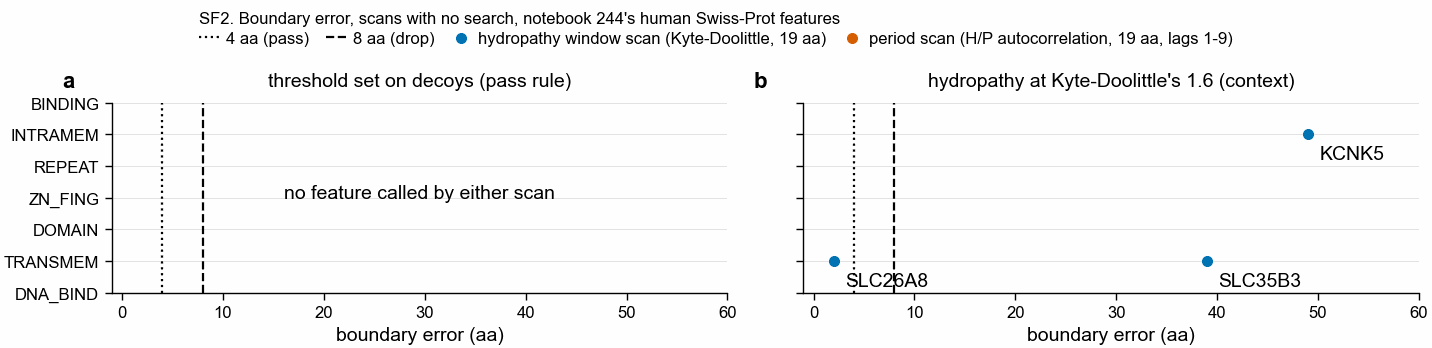

In [5]:
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 45, ncols=2, sharey=True)
for ax, rule, title in zip(
    axs,
    [DECOY_RULE, KD_RULE],
    [
        "threshold set on decoys (pass rule)",
        "hydropathy at Kyte-Doolittle's 1.6 (context)",
    ],
):
    ax.axvline(ERROR_PASS, color="black", ls=":", lw=0.8, label="4 aa (pass)")
    ax.axvline(ERROR_DROP, color="black", ls="--", lw=0.8, label="8 aa (drop)")
    sub = feats.filter((pl.col("threshold_rule") == rule) & pl.col("recalled"))
    for scan in SCAN_COLOUR:
        s = sub.filter(pl.col("scan") == scan)
        yv = [types.index(t) for t in s["feature_type"]]
        ax.scatter(
            s["boundary_error_aa"],
            yv,
            color=SCAN_COLOUR[scan],
            s=12,
            label=SCAN_LABEL[scan],
            zorder=3,
        )
        for x, yy, g in zip(s["boundary_error_aa"], yv, s["gene"]):
            ax.annotate(g, (x, yy), xytext=(4, -9), textcoords="offset points")
    if sub.height == 0:
        ax.text(
            0.5,
            0.5,
            "no feature called by either scan",
            transform=ax.transAxes,
            ha="center",
        )
    ax.set_yticks(range(len(types)), types)
    ax.set_xlim(-1, 60)
    ax.set_xlabel("boundary error (aa)")
    ax.set_title(title)
    ax.grid(axis="y", color="#dddddd", lw=0.3)
axs[0].invert_yaxis()
for ax, letter in zip(axs, "ab"):
    pf.panel_label(ax, letter)
pf.shared_legend(
    fig,
    ncol=4,
    title=(
        "SF2. Boundary error, scans with no search, notebook 244's human Swiss-Prot features"
    ),
    alignment="left",
)
pf.save(
    fig, FIG / "301_sf2_scan_boundary_error_nb244_swissprot", formats=("png", "pdf")
)
print(
    feats.filter(pl.col("recalled")).select(
        "scan",
        "threshold_rule",
        "gene",
        "query",
        "feature_type",
        "feature_start",
        "feature_end",
        "call_start",
        "call_end",
        "overlap_aa",
        "boundary_error_aa",
    )
)

### The residues of every feature a scan called

For each call: the human feature's residues and the call's residues on the same protein
(1-based, inclusive), with `|` under the residues the two share. Then the feature reversed,
as it sits in its decoy, with the best 19-residue hydropathy window over it. Windows that lie
wholly inside the feature have the same means when the feature is reversed. Windows that
reach into the flanks change, which is why the reversed copy can score a little higher than
the real feature.

In [6]:
called = feats.filter((pl.col("threshold_rule") == KD_RULE) & pl.col("recalled"))
for r in called.iter_rows(named=True):
    p = human[r["query"]]
    s, e, cs, ce = r["feature_start"], r["feature_end"], r["call_start"], r["call_end"]
    lo, hi = min(s, cs), max(e, ce)
    feat_line = "".join(p[i - 1] if s <= i <= e else " " for i in range(lo, hi + 1))
    call_line = "".join(p[i - 1] if cs <= i <= ce else " " for i in range(lo, hi + 1))
    match = "".join(
        "|" if (s <= i <= e and cs <= i <= ce) else " " for i in range(lo, hi + 1)
    )
    print(
        f"{r['gene']} {r['query']} {r['feature_type']}  feature {s}-{e} ({e - s + 1} aa), "
        f"call {cs}-{ce}, {r['overlap_aa']} of {e - s + 1} feature residues inside the call, "
        f"boundary error {r['boundary_error_aa']} aa"
    )
    print(f"  feature {lo:>5} {feat_line}")
    print(f"          {'':>5} {match}")
    print(f"  call    {lo:>5} {call_line}")
    key = f"{r['query']}|{s}-{e}|reversed"
    real_best = s1.best_window_over(s1.hydropathy_windows(p), s, e)
    rev_best = s1.best_window_over(s1.hydropathy_windows(decoy_seqs[key]), s, e)
    print(f"  reversed {p[s - 1:e][::-1]}")
    print(
        f"  best window mean over the feature: real {real_best:.2f}, reversed decoy {rev_best:.2f}\n"
    )

KCNK5 O95279 INTRAMEM  feature 85-112 (28 aa), call 112-134, 1 of 28 feature residues inside the call, boundary error 49 aa
  feature    85 WPNAMIFAATVITTIGYGNVAPKTPAGR                      
                                           |                      
  call       85                            RLFCVFYGLFGVPLCLTWISALG
  reversed RGAPTKPAVNGYGITTIVTAAFIMANPW
  best window mean over the feature: real 1.67, reversed decoy 1.86

SLC26A8 Q96RN1 TRANSMEM  feature 393-413 (21 aa), call 393-411, 19 of 21 feature residues inside the call, boundary error 2 aa
  feature   393 LIAIGLCNVVSSFFRSCVFTG
                |||||||||||||||||||  
  call      393 LIAIGLCNVVSSFFRSCVF  
  reversed GTFVCSRFFSSVVNCLGIAIL
  best window mean over the feature: real 1.77, reversed decoy 1.88

SLC35B3 Q9H1N7 TRANSMEM  feature 324-346 (23 aa), call 299-332, 9 of 23 feature residues inside the call, boundary error 39 aa
  feature   299                          LIAVTVTTGRKAMTIVLSFIFFA
                               

### Step 1 verdict

- At the threshold where fewer than 1% of the 100 decoy windows are hit, the hydropathy
  window scan recalls 0 of 50 features (0 of 87 cases), and so does the period scan. Under
  the pass rule both are DROP: recall is below 50%. Neither meets the pass rule, so kmerseek
  is not held to a scan's bar on these cases; it is held to HMMER and MMseqs2 as planned.
- The scans fail for one reason. A feature's best window scores no higher than the best
  window of its own residues reversed or pair-shuffled. In SF1a, recall is never more than
  0.05 (hydropathy) or 0.10 (period) above the decoy hit rate at any threshold. On these 50 features, composition-preserving decoys leave little separation for
  either scan. This does not establish that every composition scan must fail every
  composition-preserving control.
- At Kyte and Doolittle's own cutoff of 1.6 the hydropathy scan calls 3 of 50 features and
  hits 7 of 100 decoy windows. Its boundary errors on those 3 are 2, 39 and 49 residues
  (SF2b). These cases are mostly not membrane features, which is why notebook 244 chose them.
- The 87 cases are not the main test's feature types. They are BINDING (31), INTRAMEM (16),
  REPEAT (13), ZN_FING (13), DOMAIN (8), TRANSMEM (4) and DNA_BIND (2). No signal peptide,
  transit peptide or ELM motif. The step 2 query set is where the scans meet the four main
  types; step 1 does not tell us how a scan does on signal peptides.

## 2. Step 2: the query set

Built on Sherlock by `scripts/301_step2.sbatch` (job 48677933, 2026-10-20, 24 minutes)
from Swiss-Prot release 2026_03 (02-Sep-2026, `uniprot_sprot.dat.gz` SHA-256 c8720882...)
and the ELM true-positive table from closed PR 181 (`data/301_short_feature_boundaries/SOURCES.md`).
The tables read here are in `data/301_short_feature_boundaries/step2/`.

- **Real queries.** 1,000 human and 1,000 microbial (Bacteria or Archaea) Swiss-Prot
  proteins, drawn at random (seed 301) from every protein with at least one feature: a
  SIGNAL, TRANSIT or TRANSMEM span with experimental evidence (ECO:0000269) shorter than
  60 residues, or an ELM true-positive instance. Every feature of a chosen protein is
  recorded.
- **Chimeras.** 500 host proteins with no SIGNAL or TRANSIT feature and no ELM degron,
  100 to 1,000 residues, half human and half microbial. Each gets `GGGGSGGGGS` and then one
  insert at a random position at least 10 residues from either end. The inserts are every
  ELM degron instance on a Swiss-Prot entry (177) and 323 experimental signal peptides, none
  used twice.
- **Leave-self-out.** Each real query, chimera host and insert source was looked up in
  UniRef90 (2,843 accessions, 2,778 clusters), and every Swiss-Prot member of those clusters
  was left out of the search database.

shape: (11, 5)
┌────────────┬────────────────┬──────────────┬────────────┬───────────┐
│ query_kind ┆ organism_group ┆ feature_type ┆ n_features ┆ n_queries │
│ ---        ┆ ---            ┆ ---          ┆ ---        ┆ ---       │
│ str        ┆ str            ┆ str          ┆ i64        ┆ i64       │
╞════════════╪════════════════╪══════════════╪════════════╪═══════════╡
│ chimera    ┆ human          ┆ ELM          ┆ 96         ┆ 96        │
│ chimera    ┆ human          ┆ SIGNAL       ┆ 154        ┆ 154       │
│ chimera    ┆ microbial      ┆ ELM          ┆ 81         ┆ 81        │
│ chimera    ┆ microbial      ┆ SIGNAL       ┆ 169        ┆ 169       │
│ real       ┆ human          ┆ ELM          ┆ 974        ┆ 565       │
│ real       ┆ human          ┆ SIGNAL       ┆ 305        ┆ 305       │
│ real       ┆ human          ┆ TRANSIT      ┆ 32         ┆ 32        │
│ real       ┆ human          ┆ TRANSMEM     ┆ 979        ┆ 141       │
│ real       ┆ microbial      ┆ ELM          ┆ 53

shape: (4, 4)
┌──────────────┬──────┬──────────────────┬────────────────────────────┐
│ feature_type ┆ n    ┆ median_length_aa ┆ frac_shorter_than_median_k │
│ ---          ┆ ---  ┆ ---              ┆ ---                        │
│ str          ┆ u32  ┆ f64              ┆ f64                        │
╞══════════════╪══════╪══════════════════╪════════════════════════════╡
│ ELM          ┆ 1204 ┆ 6.0              ┆ 0.963                      │
│ SIGNAL       ┆ 1456 ┆ 24.0             ┆ 0.019                      │
│ TRANSIT      ┆ 32   ┆ 31.5             ┆ 0.062                      │
│ TRANSMEM     ┆ 1910 ┆ 21.0             ┆ 0.158                      │
└──────────────┴──────┴──────────────────┴────────────────────────────┘


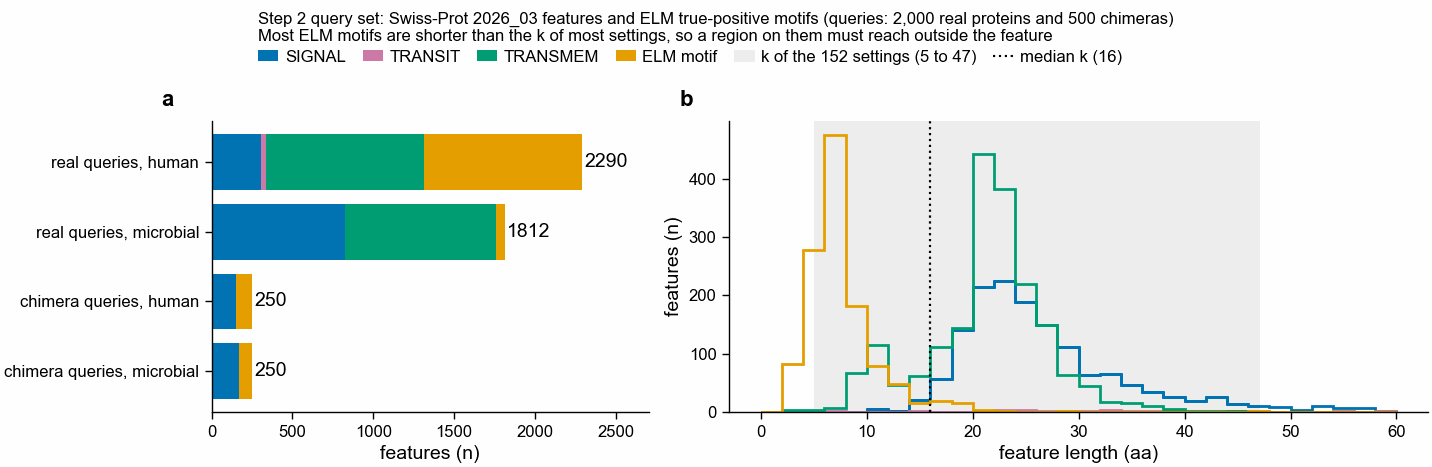

In [7]:
S2 = DATA / "step2"
truth = pl.read_csv(S2 / "truth.tsv", separator="\t")
counts2 = pl.read_csv(S2 / "feature_type_counts.tsv", separator="\t")
filt = pl.read_csv(S2 / "filter_counts.tsv", separator="\t")
uref = pl.read_csv(S2 / "uniref90_counts.tsv", separator="\t")
print(counts2)
print(filt)
print(uref)

plan241 = pl.read_json("241_plan.json")
ks = plan241["ksize"].to_numpy()
TYPE_ORDER = ["SIGNAL", "TRANSIT", "TRANSMEM", "ELM"]
TYPE_COLOUR = {
    "SIGNAL": pf.OKABE_ITO["blue"],
    "TRANSIT": pf.OKABE_ITO["reddish_purple"],
    "TRANSMEM": pf.OKABE_ITO["bluish_green"],
    "ELM": pf.OKABE_ITO["orange"],
}
fig, axs = pf.figure(
    pf.TWO_COLUMN_MM, 60, ncols=2, gridspec_kw={"width_ratios": [1, 1.6]}
)
ax = axs[0]
groups = [
    ("real", "human"),
    ("real", "microbial"),
    ("chimera", "human"),
    ("chimera", "microbial"),
]
y = np.arange(len(groups))
left = np.zeros(len(groups))
for t in TYPE_ORDER:
    v = np.array(
        [
            counts2.filter(
                (pl.col("query_kind") == k)
                & (pl.col("organism_group") == g)
                & (pl.col("feature_type") == t)
            )["n_features"].sum()
            for k, g in groups
        ]
    )
    ax.barh(
        y, v, left=left, color=TYPE_COLOUR[t], label=t if t != "ELM" else "ELM motif"
    )
    left += v
for yi, tot in zip(y, left):
    ax.text(tot + 15, yi, f"{int(tot)}", va="center")
ax.set_yticks(y, [f"{k} queries, {g}" for k, g in groups])
ax.invert_yaxis()
ax.set_xlabel("features (n)")
ax.set_xlim(0, left.max() * 1.18)
ax = axs[1]
bins = np.arange(0, 61, 2)
for t in TYPE_ORDER:
    L = truth.filter(pl.col("feature_type") == t)["length_aa"].to_numpy()
    ax.hist(L, bins=bins, histtype="step", color=TYPE_COLOUR[t], lw=1)
kq = np.percentile(ks, [0, 50, 100])
ax.axvspan(
    kq[0], kq[2], color="#eeeeee", zorder=0, label="k of the 152 settings (5 to 47)"
)
ax.axvline(kq[1], color="black", ls=":", lw=0.8, label=f"median k ({kq[1]:.0f})")
ax.set_xlabel("feature length (aa)")
ax.set_ylabel("features (n)")
for ax, letter in zip(axs, "ab"):
    pf.panel_label(ax, letter)
pf.shared_legend(
    fig,
    ncol=6,
    title=(
        "Step 2 query set: Swiss-Prot 2026_03 features and ELM true-positive motifs (queries: 2,000 real proteins and 500 chimeras)\n"
        "Most ELM motifs are shorter than the k of most settings, so a region on them must reach outside the feature"
    ),
    alignment="left",
)
pf.save(fig, FIG / "301_step2_query_set_swissprot_elm", formats=("png", "pdf"))

by_len = (
    truth.with_columns(shorter_than_median_k=pl.col("length_aa") < float(np.median(ks)))
    .group_by("feature_type")
    .agg(
        n=pl.len(),
        median_length_aa=pl.col("length_aa").median(),
        frac_shorter_than_median_k=pl.col("shorter_than_median_k").mean().round(3),
    )
    .sort("feature_type")
)
print(by_len)

## 3. Step 3 decoys and the kmerseek pilot

**Decoys** (`scripts/build_301_step3_decoys.py`, run by `scripts/301_build.sbatch`, job
48688371, 2026-10-20). Two per feature, 9,204 in all. A decoy that cannot differ from the
real window is left out of every count: 90 pair shuffles (87 ELM motifs of 3 residues or
fewer or made of repeated pairs, and 3 transmembrane spans) and 17 reversals (ELM motifs
that read the same backwards). 9,097 decoys are used.

**Pilot** (`scripts/301_pilot_submit.sh`, jobs 48688374-48688376, 2026-10-20). kmerseek
v0.4.0 built from its tag (commit 0aed5ca), three of notebook 241's settings, the step 2
Swiss-Prot database (568,962 proteins; kmerseek indexes each distinct sequence once, which
is 482,426), and 9 queries (one per organism group and feature type, plus a signal-peptide
and a degron chimera) with their 34 decoys. Each search passed the setting's own
`--extend-mismatch-penalty` and `--extend-xdrop`. The table is
`data/301_short_feature_boundaries/pilot/pilot_summary.tsv`, column names as
`scripts/collect_301_pilot.py` wrote them.

- `region_evalue` is finite on all but 51 of 7,334,783 rows for protein20 k5 and
  hp_lehninger2 k19. The extension flags work; point 1 above is settled.
- `region_subseq` equals the query's residues at `region_start`..`region_end` on every row,
  so the 0-based, end-exclusive reading is right.
- dayhoff6 k12's Karlin-Altschul fit was refused on this index, and kmerseek v0.4.0 then
  refuses to search. Such a setting is excluded and listed, as decided.
- One query (P12241, hp_lehninger2 k19, 4 cores) took 61.5 s the first time this node read
  the index and 2.5 s the second time. The rule asks for under 0.1 s as a cold-cache median over 100 queries. This
  pilot is slower, but does not measure that median or the other settings.

shape: (5, 17)
┌───────────┬───────────┬───────┬───────────┬───────────┬───────────┬───────────┬───────────┬───────────┬───────────┬───────────┬───────────┬───────────┬───────────┬───────────┬───────────┬──────────┐
│ setting   ┆ alphabet  ┆ ksize ┆ karlin_al ┆ targets_l ┆ index_wal ┆ index_pea ┆ search_43 ┆ search_pe ┆ rows_real ┆ rows_fini ┆ rows_chim ┆ rows_fini ┆ rows_deco ┆ rows_fini ┆ rows_kept ┆ search_1 │
│ ---       ┆ ---       ┆ ---   ┆ tschul_fi ┆ oaded     ┆ l_s       ┆ k_rss_gb  ┆ _sequence ┆ ak_rss_gb ┆ ---       ┆ te_region ┆ era       ┆ te_region ┆ y         ┆ te_region ┆ _by_filte ┆ _query_4 │
│ str       ┆ str       ┆ i64   ┆ t         ┆ ---       ┆ ---       ┆ ---       ┆ s_wall_s  ┆ ---       ┆ i64       ┆ _evalue_r ┆ ---       ┆ _evalue_c ┆ ---       ┆ _evalue_d ┆ r_e10_on_ ┆ _cores_w │
│           ┆           ┆       ┆ ---       ┆ i64       ┆ f64       ┆ f64       ┆ ---       ┆ f64       ┆           ┆ eal       ┆ i64       ┆ him…      ┆ i64       ┆ eco…      ┆ win

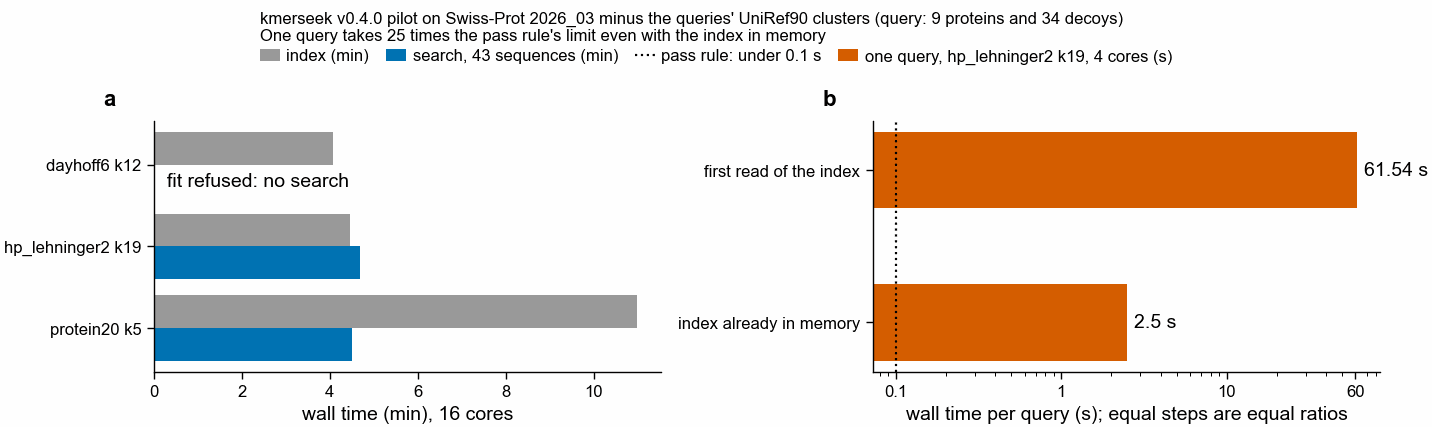

In [8]:
pilot = pl.read_csv(DATA / "pilot" / "pilot_summary.tsv", separator="\t")
print(
    pilot.select([c for c in pilot.columns if not c.startswith("rows_region_subseq")])
)

settings = pilot.filter(pl.col("index_wall_s").is_not_null())
one = pilot.filter(pl.col("search_1_query_4_cores_wall_s").is_not_null())
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 55, ncols=2)
ax = axs[0]
y = np.arange(settings.height)
ax.barh(
    y - 0.2,
    settings["index_wall_s"] / 60,
    height=0.4,
    color=pf.GREY,
    label="index (min)",
)
srch = settings["search_43_sequences_wall_s"].fill_null(0).to_numpy() / 60
ax.barh(
    y + 0.2,
    srch,
    height=0.4,
    color=pf.OKABE_ITO["blue"],
    label="search, 43 sequences (min)",
)
for yi, (fit, sv) in enumerate(zip(settings["karlin_altschul_fit"], srch)):
    if fit == "refused":
        ax.text(0.3, yi + 0.2, "fit refused: no search", va="center")
ax.set_yticks(y, [f"{a} k{k}" for a, k in zip(settings["alphabet"], settings["ksize"])])
ax.invert_yaxis()
ax.set_xlabel("wall time (min), 16 cores")
ax = axs[1]
labels = ["first read of the index", "index already in memory"]
ax.barh(
    [0, 1],
    one["search_1_query_4_cores_wall_s"],
    color=pf.OKABE_ITO["vermillion"],
    height=0.5,
    label="one query, hp_lehninger2 k19, 4 cores (s)",
)
ax.axvline(0.1, color="black", ls=":", lw=0.8, label="pass rule: under 0.1 s")
ax.set_xscale("log")
ax.set_xticks([0.1, 1, 10, 60], ["0.1", "1", "10", "60"])
ax.set_yticks([0, 1], labels)
ax.invert_yaxis()
ax.set_xlabel("wall time per query (s); equal steps are equal ratios")
for v, yy in zip(one["search_1_query_4_cores_wall_s"], [0, 1]):
    ax.text(v * 1.1, yy, f"{v:g} s", va="center")
for ax, letter in zip(axs, "ab"):
    pf.panel_label(ax, letter)
pf.shared_legend(
    fig,
    ncol=4,
    title=(
        "kmerseek v0.4.0 pilot on Swiss-Prot 2026_03 minus the queries' UniRef90 clusters (query: 9 proteins and 34 decoys)\n"
        "One query takes 25 times the pass rule's limit even with the index in memory"
    ),
    alignment="left",
)
pf.save(fig, FIG / "301_pilot_kmerseek_time_swissprot", formats=("png", "pdf"))

## 4. What was found while preparing steps 3 to 8

The complete benchmark is still unfinished. Six things in the task brief differ from the repository as it
stands on 2026-10-20. Each needs a decision before compute is spent.

1. **The decoys put the feature back into its real flanks.** Step 3 splices each decoy
   window into the parent protein. A homology search (MMseqs2, hmmscan, kmerseek with
   extension) that aligns the parent's homologs across the whole protein will report a
   region over the decoy window too, because the flanks are unchanged. Such a region counts
   as a decoy hit, so the 1% threshold will be set by whole-protein alignments, not by
   anything the feature's residues did. The scans above do not have this problem, because
   they read only the window.
2. **Which settings table.** Notebooks 250-253 (PRs 58, 69, 72) searched 19 settings, one
   per alphabet (`assets/elm_cover_chosen_arms.tsv`), none with extension. The count "81 of
   152 settings had no Karlin-Altschul fit" is from notebook 241's 152 settings, not from
   250-253.
3. **PR 54 is not the E-value source.** seanome/kmerseek PR 54 ("Extend matched regions past
   their exact seed, and rank them with a Karlin-Altschul E-value") was closed without
   merging. The region E-values now come from kmerseek PRs 133/134 (commit 0a22970). Notebook
   344 (PR 174) found those E-values 10-113 times too small on long, low-complexity proteins.
   The pass rule sets its threshold on decoys, so it uses the E-value only to rank regions;
   miscalibration does not change the verdict.
4. **UniRef90 may not fit two compute-days.** UniRef90 holds far more sequences than
   Swiss-Prot (its exact size is recorded on the day it is downloaded). No kmerseek index of
   that size has been built in this project. Its memory and time have to be measured on
   Swiss-Prot first and scaled before the UniRef90 run is sized.
5. **hmmscan has no database to share.** hmmscan searches each query against Pfam-A
   profiles, not against UniRef90, so "the same database" applies only to MMseqs2. Pfam has
   few families for signal or transit peptides, so hmmscan is expected to report little on
   those types.
6. **Cold cache on Sherlock.** Shared nodes do not let a user drop the page cache, so a
   cold-cache timing needs a freshly allocated node whose first read of the index is timed.
   If that cannot be confirmed, timings will be labelled warm.

### Decisions, 2026-10-20, before any kmerseek run

Olga's answers to points 1, 2 and 4 above. They are part of the rule from here on.

- **Decoy hit (point 1).** The verdict is reported under the brief's rule: a decoy is hit
  when any reported region overlaps its window. Beside it, labelled as not the rule, the
  same numbers with a region counted only when at least half its residues lie inside the
  window, for decoys and true features alike.
- **Settings (point 2).** Notebook 241's 152 settings. Those without a Karlin-Altschul fit
  (81 of 152 in notebook 241) are excluded and listed by name.
- **Database (point 4).** Swiss-Prot first, with every query's own UniRef90 cluster
  removed. Index memory and time are measured there, and UniRef90 is run only if the
  measurement shows it fits the compute left.

### Points carried over from closed PR 181, 2026-10-20

PR 181 (notebook 351) asked the same question in another chat and was closed in favour of
this notebook. A review of its preregistration raised five points; each is answered here.

1. **Extension is off by default.** In kmerseek v0.4.0, `kmerseek search` defaults to
   `--extend-mismatch-penalty 0.0` (`src/rust/main.rs` line 223 at tag v0.4.0), which keeps
   regions exact, and the Karlin-Altschul E-value is computed only for extended regions.
   Left at the default, every region would get no finite `region_evalue` and the test
   would fail for a reason that has nothing to do with boundaries. Every search here
   passes the setting's own `--extend-mismatch-penalty` and `--extend-xdrop`, and a few
   proteins are searched first to check that `region_evalue` is finite.
2. **A setting is named by all five fields.** Notebook 241's 152 settings
   (`notebooks/241_plan.json`) are: alphabet; k; scaled 1; low-complexity mask on
   (`--remove-low-complexity`); extension at the alphabet's own mismatch penalty and X-drop
   (from its measured copy rate; 2 and 8 for the one alphabet without one). "81 of 152 had
   no Karlin-Altschul fit" was counted on the human proteome. The fit is redone on the
   Swiss-Prot index, so the settings excluded here are the ones whose fit is refused on
   that index, listed by name.
3. **Why boundaries are read on the query.** The true start and end exist only on the
   query protein; the target proteins carry no annotation of the feature. kmerseek reports
   each region's query-side positions (0-based in its output, converted to 1-based here),
   and those are compared with the truth.
4. **k is longer than most features.** The median ELM motif is 6 residues (4,006
   true-positive instances under 60 residues). 140 of the 152 settings have k above 6, and
   k runs from 5 to 47. A region holds at least one exact k-mer, so on a feature shorter
   than k it must reach outside the feature, and its boundary error is at least k minus the
   feature's length. Boundary error is therefore also reported by feature length against k.
5. **What "two compute-days" means.** Read here as the wall time of all Sherlock jobs
   summed, 48 hours, kept as a running total; CPU-hours are reported beside it.

## 5. Three completed settings and recovery of the other 16 (2026-10-23)

The fixed pass rule gives DROP for each of the three completed settings on the subset:
360 queries, 685 features and 1,356 usable decoy windows. Recall is 0 at the admissible
cutoff; median boundary error is undefined because no feature is recalled. These are
partial results, not a verdict across the planned settings.

Scores come from `scripts/score_301_completed.py`. Raw filtered hits, the subset IDs and
expected chunk counts are committed under `data/301_short_feature_boundaries/partial/raw`.
The cutoff uses only decoys, pooled across feature types. A hit requires
`region_evalue < region_evalue_threshold`, so ties enter together; the cutoff is capped
at 10 because only E-values up to 10 were retained. With 1,356 decoys, at most 13 can hit.
The output has E-value zero on 55 protein20, 45 uniprot18 and 35 wass14 decoy queries.
Admitting the zero group therefore exceeds 1%; cutoff 0 rejects all hits. With an inclusive
comparison there is no admissible nonnegative cutoff. The zero values cannot be ordered
using this output. The pass rule itself remains unchanged.

The half-inside diagnostic, requested before the run and not used for the verdict,
recalls 100, 95 and 84 of 685 features, with median boundary errors 15.5, 17 and 16 aa.
Boundary error is conditional on recall. When several regions overlap one feature, choose
largest overlap, then lower E-value, then target name and coordinates. Overlap fraction
is residues in common divided by feature length. Per-type results and E=10 context are
in the summary table. Thresholds are not fitted separately per feature type.

Seven jobs hit 96 GiB during the 200-query Karlin–Altschul calibration; nine hit it during
search. Failed RSS is a lower bound because Slurm killed each process at its memory limit.
The recovery requests are 256 GiB for calibration failures and 192 GiB for search failures,
with 12 h limits except hp_thomas_dill2 (10 h, seven chunks already complete). These are
requests, not measured successful peaks. `scripts/measure_301_recovery.py` recomputes them
from accounting and GNU time logs at submission. Original accounting and logs are committed.

The recovery also fixes index reuse: RocksDB's CURRENT exists before calibration ends,
so reuse now requires the index log's final success line. Interrupted builds are retained
and rebuilt. Completed chunks are checked with gzip and reused with the original
100-sequence boundaries. Tests simulate a killed index with CURRENT present and a finished
chunk; the index is rebuilt and the chunk is reused.

Jobs 49182599–49182614 were submitted on 2026-10-23. Their success and peak memory are not
yet measured. The one-query pilot (2.5 s warm) is not the required 100-query cold-cache
median. It cannot by itself establish a timing verdict for all settings. Comparators,
full timing and the independent second-agent check remain outstanding. The earlier
statement that the pilot ruled out PASS for every setting was too strong.

shape: (6, 15)
┌─────────────┬─────────────┬─────────────┬─────────────┬────────────┬────────────┬────────────┬────────────┬────────────┬────────────┬────────────┬────────────┬────────────┬────────────┬────────────┐
│ setting     ┆ rule        ┆ cutoff_kind ┆ feature_typ ┆ region_eva ┆ n_features ┆ n_recalled ┆ recall_fea ┆ n_decoy_wi ┆ n_decoys_h ┆ n_decoys_z ┆ decoy_hit_ ┆ median_bou ┆ median_ove ┆ partial_qu │
│ ---         ┆ ---         ┆ ---         ┆ e           ┆ lue_thresh ┆ ---        ┆ ---        ┆ tures      ┆ ndows      ┆ it         ┆ ero_evalue ┆ rate       ┆ ndary_erro ┆ rlap_fract ┆ ality_verd │
│ str         ┆ str         ┆ str         ┆ ---         ┆ old        ┆ i64        ┆ i64        ┆ ---        ┆ ---        ┆ ---        ┆ ---        ┆ ---        ┆ r_aa       ┆ ion        ┆ ict        │
│             ┆             ┆             ┆ str         ┆ ---        ┆            ┆            ┆ f64        ┆ i64        ┆ i64        ┆ i64        ┆ f64        ┆ ---        ┆ ---   

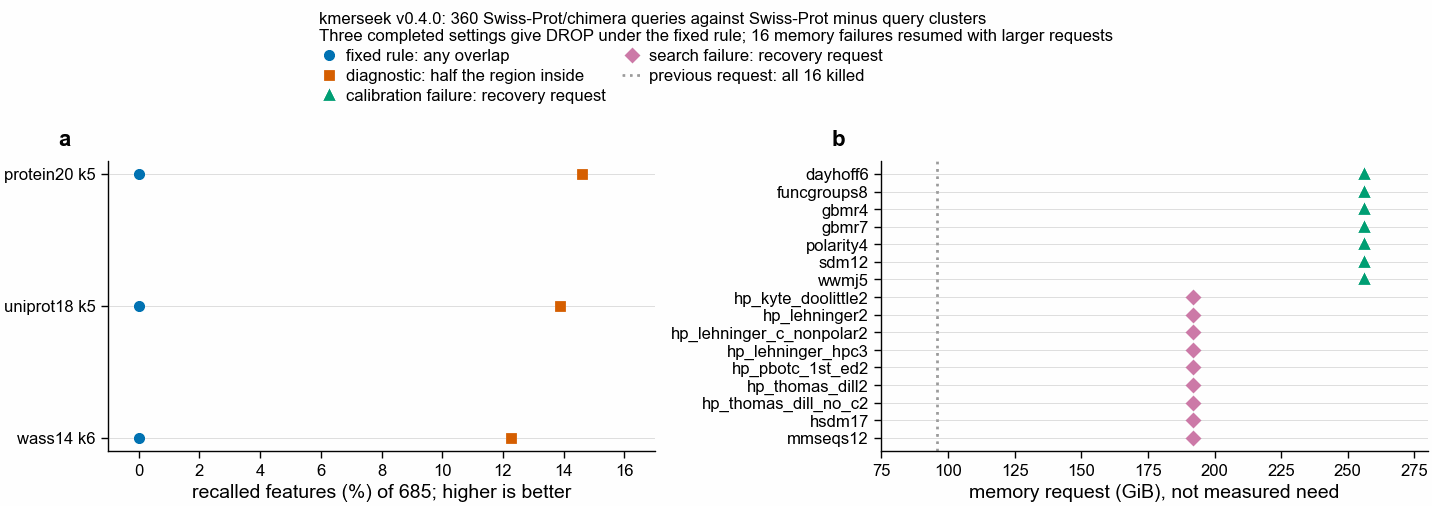

In [9]:
partial = pl.read_csv(
    DATA / "partial" / "301_partial_summary_swissprot.tsv",
    separator="\t",
    null_values="NA",
)
shown = partial.filter(
    (pl.col("feature_type") == "all") & (pl.col("cutoff_kind") == "decoy_threshold")
)
print(shown)
resources = pl.read_csv(
    DATA / "partial" / "301_recovery_resources_swissprot.tsv", separator="\t"
)
print(resources)
labels = ["protein20 k5", "uniprot18 k5", "wass14 k6"]
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 65, ncols=2)
for rule, colour, marker, label in [
    ("any_overlap", pf.OKABE_ITO["blue"], "o", "fixed rule: any overlap"),
    (
        "half_region_inside",
        pf.OKABE_ITO["vermillion"],
        "s",
        "diagnostic: half the region inside",
    ),
]:
    vals = shown.filter(pl.col("rule") == rule).sort("setting")
    axs[0].plot(
        vals["recall_features"].to_numpy() * 100,
        np.arange(3),
        marker=marker,
        ls="none",
        color=colour,
        label=label,
    )
axs[0].set_yticks(np.arange(3), labels)
axs[0].invert_yaxis()
axs[0].set_xlim(-1, 17)
axs[0].set_xlabel("recalled features (%) of 685; higher is better")
axs[0].grid(axis="y")
r = resources.filter(pl.col("previous_state") == "OUT_OF_MEMORY").sort(
    "failure_stage", "alphabet"
)
for stage, colour, marker, label in [
    (
        "index",
        pf.OKABE_ITO["bluish_green"],
        "^",
        "calibration failure: recovery request",
    ),
    ("search", pf.OKABE_ITO["reddish_purple"], "D", "search failure: recovery request"),
]:
    idx = [i for i, x in enumerate(r["failure_stage"]) if x == stage]
    axs[1].plot(
        [r["requested_memory_gib"][i] for i in idx],
        idx,
        ls="none",
        marker=marker,
        color=colour,
        label=label,
    )
axs[1].axvline(96, color=pf.GREY, ls=":", label="previous request: all 16 killed")
axs[1].set_yticks(np.arange(r.height), r["alphabet"])
axs[1].invert_yaxis()
axs[1].set_xlim(75, 280)
axs[1].set_xlabel("memory request (GiB), not measured need")
axs[1].grid(axis="y")
for ax, letter in zip(axs, "ab"):
    pf.panel_label(ax, letter)
pf.shared_legend(
    fig,
    ncol=2,
    title=(
        "kmerseek v0.4.0: 360 Swiss-Prot/chimera queries against Swiss-Prot minus query clusters\n"
        "Three completed settings give DROP under the fixed rule; 16 memory failures resumed with larger requests"
    ),
    alignment="left",
)
pf.save(fig, FIG / "301_partial_scores_recovery_swissprot", formats=("png", "pdf"))

## Summary and conclusions

1. On notebook 244's 87 cases (50 human Swiss-Prot features), the hydropathy window scan and
   the period scan each recall 0 features at a decoy hit rate below 1%: DROP under the pass
   rule (SF1, table in section 1).
2. Both scans score a feature's reversed or pair-shuffled residues about as high as the
   feature itself: at every threshold, recall is at most 0.05 (hydropathy) or 0.10 (period)
   above the decoy hit rate (SF1a).
3. At its published cutoff of 1.6, the Kyte-Doolittle scan calls 3 of 50 features with
   boundary errors of 2, 39 and 49 residues, while hitting 7 of 100 decoys (SF2b).
4. Step 1 sets no scan bar for kmerseek on these cases: neither scan passes, so kmerseek is
   compared with HMMER and MMseqs2.
5. The step 2 query set holds 2,000 real Swiss-Prot proteins and 500 chimeras with 4,602
   features. Leaving out every query's UniRef90 cluster removes 6,786 of 575,748 Swiss-Prot
   entries, so the search database holds 568,962 (section 2).
6. Three completed settings each recall 0 of 685 features at the decoy-set cutoff: partial DROP. The other 16 settings were resumed after memory failures (section 5). Comparators and the required timing and independent check remain outstanding.